In [1]:
print("""
AIM:

To implement Random Forest and AdaBoost ensemble learning
algorithms using Scikit-learn, develop a neural network
classifier using TensorFlow and Keras, and compare the
performance of all three models on a classification dataset.
""")



AIM:

To implement Random Forest and AdaBoost ensemble learning
algorithms using Scikit-learn, develop a neural network
classifier using TensorFlow and Keras, and compare the
performance of all three models on a classification dataset.



In [2]:
print("""
DATASET DESCRIPTION:

Dataset Name: Breast Cancer Wisconsin (Diagnostic)

Source: Scikit-learn built-in dataset.

Number of Samples: 569

Number of Features: 30 numerical features.

Target Variable: Tumour classification.

Class 0: Malignant tumour.

Class 1: Benign tumour.

The dataset contains numerical measurements of cell
nuclei, including radius, texture, perimeter, area,
and concave points.

This dataset is suitable for binary classification
and helps evaluate the performance of different
machine learning algorithms.
""")


DATASET DESCRIPTION:

Dataset Name: Breast Cancer Wisconsin (Diagnostic)

Source: Scikit-learn built-in dataset.

Number of Samples: 569

Number of Features: 30 numerical features.

Target Variable: Tumour classification.

Class 0: Malignant tumour.

Class 1: Benign tumour.

The dataset contains numerical measurements of cell
nuclei, including radius, texture, perimeter, area,
and concave points.

This dataset is suitable for binary classification
and helps evaluate the performance of different
machine learning algorithms.



In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Class labels:", dict(enumerate(dataset.target_names)))

Feature matrix shape: (569, 30)
Target vector shape: (569,)
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Class counts (0 = malignant, 1 = benign):
target
0    212
1    357
Name: count, dtype: int64


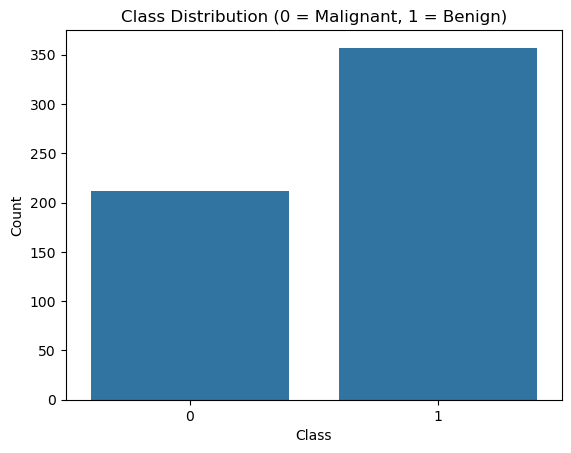

In [6]:
display(X.head())
display(X.describe())

print("Class counts (0 = malignant, 1 = benign):")
print(y.value_counts().sort_index())

sns.countplot(x=y)
plt.title("Class Distribution (0 = Malignant, 1 = Benign)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [7]:
print("Data types:")
print(X.dtypes.value_counts())
print("\nTotal missing values:", X.isnull().sum().sum())
print("Any missing values:", X.isnull().values.any())

Data types:
float64    30
Name: count, dtype: int64

Total missing values: 0
Any missing values: False


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training mean (approximately 0):", round(X_train_scaled.mean(), 3))
print("Scaled training standard deviation (approximately 1):", round(X_train_scaled.std(), 3))


Scaled training mean (approximately 0): -0.0
Scaled training standard deviation (approximately 1): 1.0


In [10]:
param_options = [
    {"n_estimators": 100, "max_depth": 4},
    {"n_estimators": 200, "max_depth": 6},
    {"n_estimators": 300, "max_depth": None}
]

best_score = -1
best_params = None

for params in param_options:
    candidate = RandomForestClassifier(random_state=RANDOM_SEED, **params)
    scores = cross_val_score(candidate, X_train, y_train, cv=5, scoring="accuracy")
    print(params, "-> mean CV accuracy:", round(scores.mean(), 4))
    if scores.mean() > best_score:
        best_score = scores.mean()
        best_params = params

print("\nSelected hyperparameters:", best_params)

rf_model = RandomForestClassifier(random_state=RANDOM_SEED, **best_params)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest training complete.")

{'n_estimators': 100, 'max_depth': 4} -> mean CV accuracy: 0.9516
{'n_estimators': 200, 'max_depth': 6} -> mean CV accuracy: 0.956
{'n_estimators': 300, 'max_depth': None} -> mean CV accuracy: 0.9582

Selected hyperparameters: {'n_estimators': 300, 'max_depth': None}
Random Forest training complete.


In [11]:
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED),
    n_estimators=200,
    learning_rate=1.0,
    random_state=RANDOM_SEED
)
ada_model.fit(X_train, y_train)
ada_pred = ada_model.predict(X_test)

ada_cv_scores = cross_val_score(ada_model, X_train, y_train, cv=5, scoring="accuracy")
print("AdaBoost cross-validation accuracy scores:", np.round(ada_cv_scores, 4))
print("Mean cross-validation accuracy:", round(ada_cv_scores.mean(), 4))
print("AdaBoost training complete.")

AdaBoost cross-validation accuracy scores: [0.967  0.989  0.9341 0.978  0.989 ]
Mean cross-validation accuracy: 0.9714
AdaBoost training complete.


In [12]:
keras_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

keras_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

keras_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Neural network training complete.


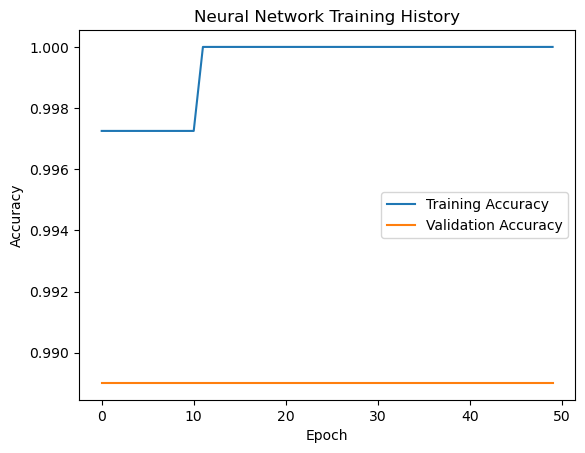

In [14]:
history = keras_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=0
)

print("Neural network training complete.")

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Training History")
plt.legend()
plt.show()

In [15]:
keras_prob = keras_model.predict(X_test_scaled, verbose=0)
keras_pred = (keras_prob > 0.5).astype(int).flatten()

print("Predictions generated for all three models.")

Predictions generated for all three models.


In [16]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

results = [
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("AdaBoost", y_test, ada_pred),
    evaluate_model("Neural Network (TensorFlow/Keras)", y_test, keras_pred)
]

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Random Forest,0.9474,0.9583,0.9583,0.9583
AdaBoost,0.9649,0.9474,1.0000,0.9730
Neural Network (TensorFlow/Keras),0.9825,0.9861,0.9861,0.9861


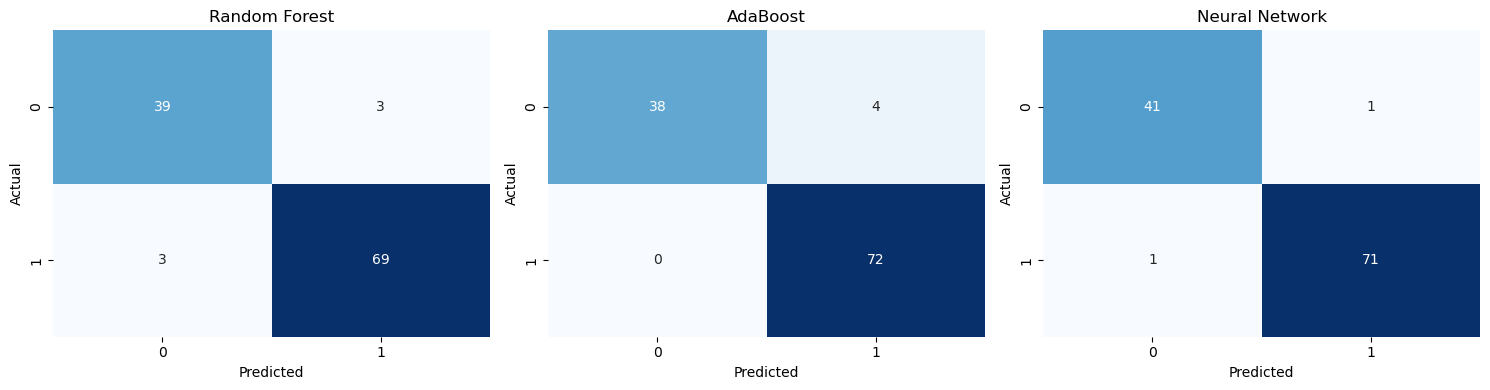

In [17]:
predictions = {
    "Random Forest": rf_pred,
    "AdaBoost": ada_pred,
    "Neural Network": keras_pred
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Accuracy,Precision,Recall,F1-score
Model,,,,
Random Forest,0.9474,0.9583,0.9583,0.9583
AdaBoost,0.9649,0.9474,1.0000,0.9730
Neural Network (TensorFlow/Keras),0.9825,0.9861,0.9861,0.9861


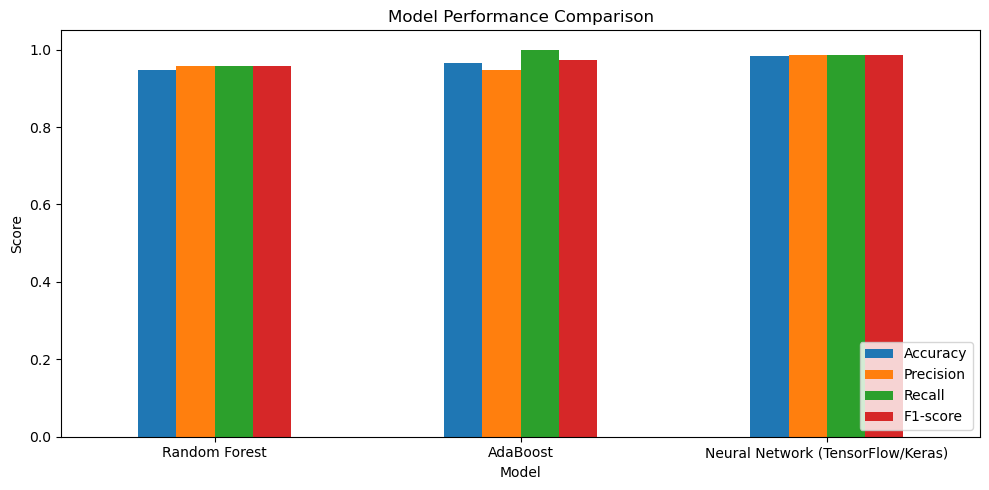

In [18]:
display(results_df.round(4))

results_df.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

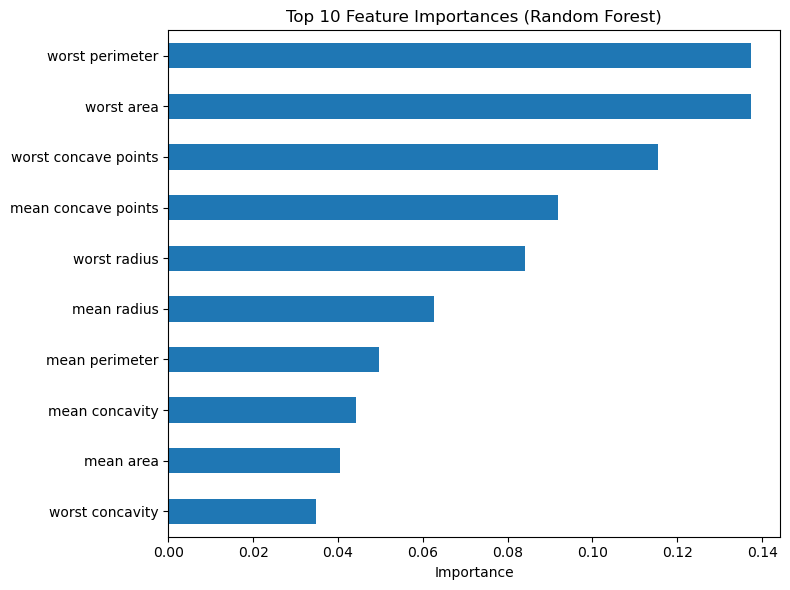

,Importance
worst perimeter,0.137344
worst area,0.137312
worst concave points,0.115502
mean concave points,0.091774
worst radius,0.084111
mean radius,0.062741
mean perimeter,0.049680
mean concavity,0.044142
mean area,0.040508
worst concavity,0.034837


In [19]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(10)

top_features.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(top_features.to_frame(name="Importance"))

In [20]:
print("RANDOM FOREST REPORT")
print(classification_report(y_test, rf_pred, target_names=dataset.target_names, zero_division=0))

print("ADABOOST REPORT")
print(classification_report(y_test, ada_pred, target_names=dataset.target_names, zero_division=0))

print("NEURAL NETWORK REPORT")
print(classification_report(y_test, keras_pred, target_names=dataset.target_names, zero_division=0))

RANDOM FOREST REPORT
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

ADABOOST REPORT
              precision    recall  f1-score   support

   malignant       1.00      0.90      0.95        42
      benign       0.95      1.00      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

NEURAL NETWORK REPORT
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg   

In [21]:
print("""
CONCLUSION:

In this experiment, Random Forest and AdaBoost ensemble
learning algorithms were implemented using Scikit-learn,
and a neural network was developed using TensorFlow
and Keras.

The models were trained and tested on the Breast Cancer
Wisconsin dataset. Their performance was compared using
accuracy, precision, recall, F1-score, and confusion
matrices.

Random Forest was also used to identify important
features in the dataset. The experiment demonstrated
how ensemble learning and neural networks can be
applied to classification problems and evaluated
to understand their predictive performance.
""")


CONCLUSION:

In this experiment, Random Forest and AdaBoost ensemble
learning algorithms were implemented using Scikit-learn,
and a neural network was developed using TensorFlow
and Keras.

The models were trained and tested on the Breast Cancer
Wisconsin dataset. Their performance was compared using
accuracy, precision, recall, F1-score, and confusion
matrices.

Random Forest was also used to identify important
features in the dataset. The experiment demonstrated
how ensemble learning and neural networks can be
applied to classification problems and evaluated
to understand their predictive performance.

